Using device: cpu
[MAML] Iter 020/200 | Meta-loss: 0.7651 | Meta-acc: 0.600
[MAML] Iter 040/200 | Meta-loss: 0.7529 | Meta-acc: 0.650
[MAML] Iter 060/200 | Meta-loss: 0.8059 | Meta-acc: 0.647
[MAML] Iter 080/200 | Meta-loss: 0.6878 | Meta-acc: 0.694
[MAML] Iter 100/200 | Meta-loss: 0.8645 | Meta-acc: 0.603
[MAML] Iter 120/200 | Meta-loss: 0.7821 | Meta-acc: 0.600
[MAML] Iter 140/200 | Meta-loss: 0.6389 | Meta-acc: 0.725
[MAML] Iter 160/200 | Meta-loss: 0.7848 | Meta-acc: 0.636
[MAML] Iter 180/200 | Meta-loss: 0.6900 | Meta-acc: 0.678
[MAML] Iter 200/200 | Meta-loss: 0.6332 | Meta-acc: 0.703


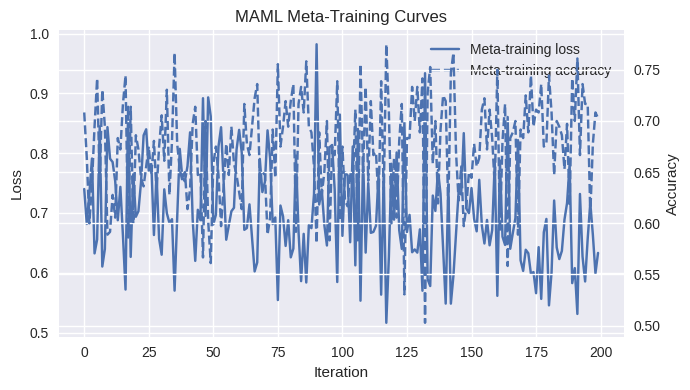


Evaluating MAML adaptation...

Evaluating Random init adaptation...

MAML adaptation results: {0: 0.3213333424925804, 1: 0.649777792096138, 3: 0.697777790427208, 5: 0.7484444576501846}
Random adaptation results: {0: 0.3297777866572142, 1: 0.645777792930603, 3: 0.7444444578886033, 5: 0.7751111233234406}


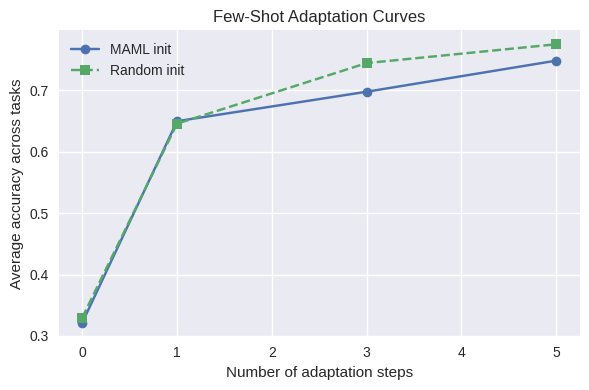

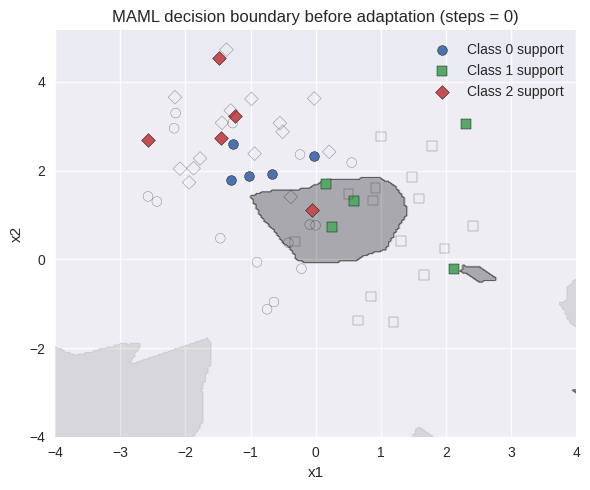

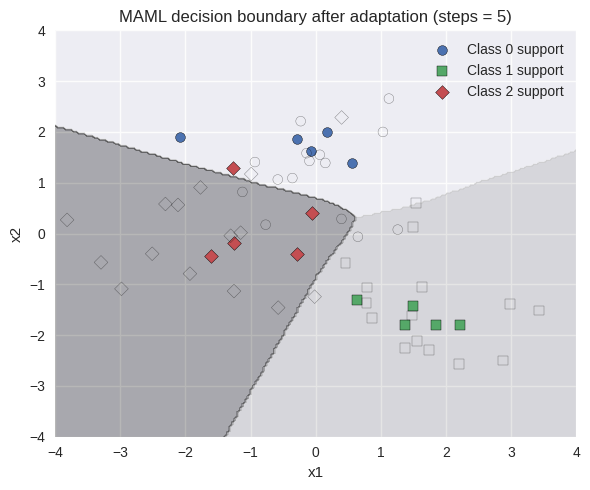

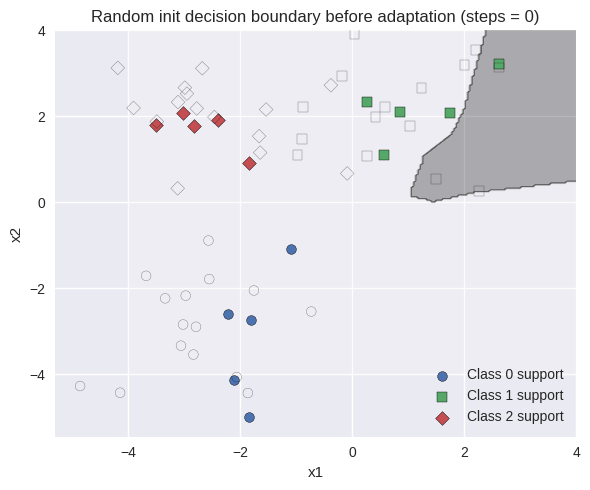

In [6]:
# ============================================================
# Meta-Learning Demo: MAML vs Random Initialisation
# Few-shot classification on synthetic 2D Gaussian tasks
# Includes: training, evaluation, and multiple plots
# ============================================================

import math
import random
from collections import OrderedDict

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

# ----------------------
# 1. Reproducibility
# ----------------------
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ----------------------
# 2. Task / Dataset setup
# ----------------------
N_WAY = 3        # number of classes per task
K_SHOT = 5       # support examples per class
Q_QUERY = 15     # query examples per class

def sample_gaussian_task(n_way=N_WAY, k_shot=K_SHOT, q_query=Q_QUERY):
    """
    Sample a few-shot classification task.
    Each class is a 2D Gaussian with random mean and variance.
    Returns support and query sets (tensors).
    """
    xs_support, ys_support = [], []
    xs_query, ys_query = [], []

    for c in range(n_way):
        mean = np.random.uniform(-3, 3, size=(2,))
        var = np.random.uniform(0.4, 1.2)  # scalar variance

        cov = np.eye(2) * var

        # support
        support_samples = np.random.multivariate_normal(mean, cov, size=k_shot)
        query_samples = np.random.multivariate_normal(mean, cov, size=q_query)

        xs_support.append(support_samples)
        ys_support.append(np.full(k_shot, c))
        xs_query.append(query_samples)
        ys_query.append(np.full(q_query, c))

    xs_support = torch.tensor(np.vstack(xs_support), dtype=torch.float32).to(device)
    ys_support = torch.tensor(np.concatenate(ys_support), dtype=torch.long).to(device)  # <- LONG!
    xs_query = torch.tensor(np.vstack(xs_query), dtype=torch.float32).to(device)
    ys_query = torch.tensor(np.concatenate(ys_query), dtype=torch.long).to(device)      # <- LONG!

    # Shuffle within each set
    perm_s = torch.randperm(xs_support.size(0))
    perm_q = torch.randperm(xs_query.size(0))

    xs_support, ys_support = xs_support[perm_s], ys_support[perm_s]
    xs_query, ys_query = xs_query[perm_q], ys_query[perm_q]

    return xs_support, ys_support, xs_query, ys_query

# ----------------------
# 3. Model definition
# ----------------------
class Encoder(nn.Module):
    """
    Simple 2-layer MLP for 2D input -> N_WAY outputs.
    Supports parameter dictionaries (for MAML inner-loop).
    """
    def __init__(self, in_dim=2, hidden_dim=40, out_dim=N_WAY):
        super().__init__()
        self.fc1 = nn.Linear(in_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, out_dim)

    def forward(self, x, params=None):
        if params is None:
            x = self.fc1(x)
            x = F.relu(x)
            x = self.fc2(x)
        else:
            # manual forward using params
            w1 = params["fc1.weight"]
            b1 = params["fc1.bias"]
            w2 = params["fc2.weight"]
            b2 = params["fc2.bias"]

            x = F.linear(x, w1, b1)
            x = F.relu(x)
            x = F.linear(x, w2, b2)
        return x

def clone_params(model):
    """
    Clone model parameters into an OrderedDict.
    """
    return OrderedDict((name, p.clone()) for (name, p) in model.named_parameters())

# ----------------------
# 4. MAML inner loop
# ----------------------
def inner_update(model, x_support, y_support, inner_steps=1, inner_lr=0.4):
    """
    Perform inner-loop gradient descent on support data.
    Returns adapted parameter dictionary.
    """
    params = clone_params(model)

    for _ in range(inner_steps):
        logits = model(x_support, params)
        loss = F.cross_entropy(logits, y_support)  # y_support MUST be Long
        grads = torch.autograd.grad(loss, params.values(), create_graph=True)

        new_params = OrderedDict()
        for (name, p), g in zip(params.items(), grads):
            new_params[name] = p - inner_lr * g
        params = new_params

    return params

# ----------------------
# 5. MAML meta-training
# ----------------------
META_ITERS = 200         # number of meta-training iterations
META_BATCH_SIZE = 8      # tasks per meta-batch
INNER_STEPS = 1
INNER_LR = 0.4
META_LR = 1e-3

def train_maml(model):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=META_LR)

    meta_loss_hist = []
    meta_acc_hist = []

    for it in range(1, META_ITERS + 1):
        optimizer.zero_grad()
        meta_loss = 0.0
        meta_acc = 0.0

        for _ in range(META_BATCH_SIZE):
            xs, ys, xq, yq = sample_gaussian_task()

            # inner loop (adaptation) on support set
            adapted_params = inner_update(
                model, xs, ys,
                inner_steps=INNER_STEPS,
                inner_lr=INNER_LR
            )

            # meta-loss on query set
            logits_q = model(xq, adapted_params)
            loss_q = F.cross_entropy(logits_q, yq)
            meta_loss += loss_q

            with torch.no_grad():
                preds_q = torch.argmax(logits_q, dim=1)
                acc = (preds_q == yq).float().mean().item()
                meta_acc += acc

        meta_loss = meta_loss / META_BATCH_SIZE
        meta_loss.backward()
        optimizer.step()

        meta_acc = meta_acc / META_BATCH_SIZE

        meta_loss_hist.append(meta_loss.item())
        meta_acc_hist.append(meta_acc)

        if it % 20 == 0:
            print(f"[MAML] Iter {it:03d}/{META_ITERS} | Meta-loss: {meta_loss.item():.4f} | Meta-acc: {meta_acc:.3f}")

    return meta_loss_hist, meta_acc_hist

# ----------------------
# 6. Evaluation utilities
# ----------------------
def evaluate_adaptation(model, steps_list=(0, 1, 3, 5), n_tasks=50, inner_lr=INNER_LR):
    """
    Evaluate a model's ability to adapt to new tasks.
    steps_list: list of inner-loop steps (0 = no adaptation).
    Returns dict: step -> average accuracy across tasks.
    """
    model.to(device)
    model.eval()

    results = {s: [] for s in steps_list}

    for _ in range(n_tasks):
        xs, ys, xq, yq = sample_gaussian_task()

        # clone initial model for each task
        base_params = clone_params(model)

        for steps in steps_list:
            if steps == 0:
                logits = model(xq, base_params)
            else:
                # adapt a copy of params
                params = base_params
                for _ in range(steps):
                    logits_s = model(xs, params)
                    loss_s = F.cross_entropy(logits_s, ys)
                    grads = torch.autograd.grad(loss_s, params.values())
                    params = OrderedDict(
                        (name, p - inner_lr * g)
                        for (name, p), g in zip(params.items(), grads)
                    )
                logits = model(xq, params)

            preds = torch.argmax(logits, dim=1)
            acc = (preds == yq).float().mean().item()
            results[steps].append(acc)

    avg_results = {s: float(np.mean(v)) for s, v in results.items()}
    return avg_results

def plot_meta_training_curves(loss_hist, acc_hist):
    """
    Plot meta-training loss and accuracy curves.
    """
    fig, ax1 = plt.subplots(figsize=(7, 4))

    ax1.plot(loss_hist, label="Meta-training loss")
    ax1.set_xlabel("Iteration")
    ax1.set_ylabel("Loss")
    ax1.grid(True)

    ax2 = ax1.twinx()
    ax2.plot(acc_hist, linestyle="--", label="Meta-training accuracy")
    ax2.set_ylabel("Accuracy")

    # Simple legend handling
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

    plt.title("MAML Meta-Training Curves")
    plt.tight_layout()
    plt.show()

def plot_adaptation_curves(maml_results, random_results, steps_list):
    """
    Line plot of accuracy vs number of inner steps for:
    - MAML initialisation
    - Random initialisation
    """
    maml_accs = [maml_results[s] for s in steps_list]
    rand_accs = [random_results[s] for s in steps_list]

    plt.figure(figsize=(6, 4))
    plt.plot(steps_list, maml_accs, marker="o", label="MAML init")
    plt.plot(steps_list, rand_accs, marker="s", linestyle="--", label="Random init")

    plt.xlabel("Number of adaptation steps")
    plt.ylabel("Average accuracy across tasks")
    plt.title("Few-Shot Adaptation Curves")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_decision_boundary(model, title="Decision boundary", steps=0, inner_lr=INNER_LR):
    """
    Visualise decision boundaries on a single sampled task, before or after adaptation.
    steps = number of inner steps on this task's support set.
    """
    model.to(device)
    model.eval()

    xs, ys, xq, yq = sample_gaussian_task()

    # create grid
    x_min = -4
    x_max = 4
    y_min = -4
    y_max = 4

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200),
    )
    grid = np.stack([xx.ravel(), yy.ravel()], axis=-1)
    grid_t = torch.tensor(grid, dtype=torch.float32).to(device)

    base_params = clone_params(model)

    if steps > 0:
        params = base_params
        for _ in range(steps):
            logits_s = model(xs, params)
            loss_s = F.cross_entropy(logits_s, ys)
            grads = torch.autograd.grad(loss_s, params.values())
            params = OrderedDict(
                (name, p - inner_lr * g)
                for (name, p), g in zip(params.items(), grads)
            )
    else:
        params = base_params

    with torch.no_grad():
        logits_grid = model(grid_t, params)
        preds_grid = torch.argmax(logits_grid, dim=1).cpu().numpy()

    Z = preds_grid.reshape(xx.shape)

    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, Z, alpha=0.3)   # background regions

    # plot support and query points
    xs_cpu = xs.cpu().numpy()
    ys_cpu = ys.cpu().numpy()
    xq_cpu = xq.cpu().numpy()
    yq_cpu = yq.cpu().numpy()

    markers = ["o", "s", "D"]
    for c in range(N_WAY):
        plt.scatter(
            xs_cpu[ys_cpu == c, 0],
            xs_cpu[ys_cpu == c, 1],
            marker=markers[c % len(markers)],
            edgecolor="k",
            label=f"Class {c} support"
        )
        plt.scatter(
            xq_cpu[yq_cpu == c, 0],
            xq_cpu[yq_cpu == c, 1],
            marker=markers[c % len(markers)],
            facecolors="none",
            edgecolor="k",
            alpha=0.5,
        )

    plt.title(title + f" (steps = {steps})")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.tight_layout()
    plt.show()

# ----------------------
# 7. Run everything
# ----------------------

# 7.1 Train MAML
maml = Encoder().to(device)
maml_loss_hist, maml_acc_hist = train_maml(maml)

# Plot meta-training curves
plot_meta_training_curves(maml_loss_hist, maml_acc_hist)

# 7.2 Random initialisation baseline (no meta-training)
random_model = Encoder().to(device)
# (kept untrained as a baseline)

# 7.3 Evaluate adaptation for both models
steps_list = [0, 1, 3, 5]
print("\nEvaluating MAML adaptation...")
maml_results = evaluate_adaptation(maml, steps_list=steps_list, n_tasks=50, inner_lr=INNER_LR)

print("\nEvaluating Random init adaptation...")
random_results = evaluate_adaptation(random_model, steps_list=steps_list, n_tasks=50, inner_lr=INNER_LR)

print("\nMAML adaptation results:", maml_results)
print("Random adaptation results:", random_results)

# Plot adaptation curves
plot_adaptation_curves(maml_results, random_results, steps_list)

# 7.4 Decision boundary plots for a single task
# Before adaptation (steps = 0)
plot_decision_boundary(maml, title="MAML decision boundary before adaptation", steps=0)

# After a few inner steps on that task
plot_decision_boundary(maml, title="MAML decision boundary after adaptation", steps=5)

# You can also visualise random initialisation if you like:
plot_decision_boundary(random_model, title="Random init decision boundary before adaptation", steps=0)
